[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/12-data-annotation-and-rlhf/notebooks/02-reward-model.ipynb)

# 02 - Train a tiny reward model on preference pairs

**Goal:** see stage 2 of RLHF with your own eyes. We create synthetic **preference pairs** (prompt, chosen answer, rejected answer), train a tiny **reward model** that gives a score to any answer, and then find a weakness in it (**reward hacking**).

**Words you need**
- **Reward model** - a model that reads an answer and outputs one number: how much a human would like it.
- **Preference pair** - two answers to the same prompt where a human marked one as better (**chosen**) and one as worse (**rejected**).
- **Bradley-Terry loss** - `-log(sigmoid(r_chosen - r_rejected))`; small when the chosen answer scores higher.

A real reward model is a full LLM with a scoring head. Ours is a **linear model on word counts** so that it trains in a second on a CPU and we can read what it learned.

## Step 1 - Imports and a fixed random seed

A **seed** makes random numbers repeatable, so everyone in class sees the same results.

In [1]:
import random
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
random.seed(0); torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.15.0+cpu


## Step 2 - Build synthetic preference data

Real preference data comes from human annotators. To keep this offline we *generate* it from templates:
- **chosen** answers are polite and contain real steps;
- **rejected** answers are rude, dismissive, or polite but empty (no actual help).

The "polite but empty" ones matter: they stop the model from learning "polite words = good" and force it to look for real content.

In [2]:
topics = [
    ("reset my password", "open Settings, choose Security, then click Reset password and follow the email link"),
    ("cook rice", "rinse one cup of rice, add two cups of water, boil, then simmer covered for 15 minutes"),
    ("learn Python", "start with variables and loops, practise daily on small projects, and read other people's code"),
    ("fix a flat bicycle tyre", "remove the wheel, find the hole, patch the tube, and pump it to the right pressure"),
    ("save money", "track your spending for a month, set a budget, and move savings first each payday"),
    ("sleep better", "keep a fixed bedtime, avoid screens for an hour before bed, and keep the room dark"),
    ("write a CV", "list recent experience first, use clear headings, and keep it to one or two pages"),
    ("make tea", "boil water, steep the tea for three minutes, then add milk or sugar if you like"),
    ("back up my phone", "turn on cloud backup in settings or copy your photos to a computer each week"),
    ("prepare for an interview", "research the company, practise common questions aloud, and prepare questions to ask"),
    ("start running", "begin with short run-walk sessions three times a week and increase slowly"),
    ("plant tomatoes", "choose a sunny spot, plant seedlings deep, water at the base, and add a support stake"),
]
openers = ["Sure! Here is how:", "Happy to help.", "Good question.", "Of course."]
closers = ["Hope this helps!", "Let me know if you have questions.", "Good luck!", ""]
bad_answers = [
    lambda t: "Figure it out yourself.",
    lambda t: "I don't know, search online.",
    lambda t: f"Why would you want to {t}? That's a silly question.",
    lambda t: "Just do it. It's easy.",
    lambda t: f"Sure! Happy to help. Good luck with trying to {t}!",   # polite but empty
    lambda t: "Of course. Hope this helps! Let me know if you have questions.",  # polite but empty
]

pairs = []
for t, steps in topics:
    for _ in range(10):
        prompt = random.choice([f"How do I {t}?", f"Can you tell me how to {t}?", f"What's the best way to {t}?"])
        chosen = f"{random.choice(openers)} To {t}, {steps}. {random.choice(closers)}".strip()
        rejected = random.choice(bad_answers)(t)
        pairs.append({"prompt": prompt, "chosen": chosen, "rejected": rejected})
random.shuffle(pairs)
print(len(pairs), "pairs. Example:")
pairs[0]

120 pairs. Example:


{'prompt': "What's the best way to sleep better?",
 'chosen': 'Happy to help. To sleep better, keep a fixed bedtime, avoid screens for an hour before bed, and keep the room dark. Good luck!',
 'rejected': "I don't know, search online."}

## Step 3 - Train / test split by topic

We hold out three whole topics for testing. If the reward model scores *unseen topics* correctly, it learned something general ("real steps beat dismissive replies"), not just memorised sentences.

In [3]:
test_topics = {"start running", "plant tomatoes", "prepare for an interview"}
is_test = lambda p: any(t in p["prompt"] for t in test_topics)
train = [p for p in pairs if not is_test(p)]
test = [p for p in pairs if is_test(p)]
print("train pairs:", len(train), " test pairs:", len(test))

train pairs: 90  test pairs: 30


## Step 4 - Turn text into numbers

Models only understand numbers. A **CountVectorizer** builds a **vocabulary** (list of known words) and turns each answer into a vector of word counts - a "bag of words". Each word gets one column. We drop **stop words** (very common words such as "the" and "and") so the learned weights are easier to read.

In [4]:
vec = CountVectorizer(lowercase=True, stop_words="english")   # drop very common words like 'the', 'and'
vec.fit([p["chosen"] for p in train] + [p["rejected"] for p in train])
def feats(texts):
    return torch.tensor(vec.transform(texts).toarray(), dtype=torch.float32)

Xc_train, Xr_train = feats([p["chosen"] for p in train]), feats([p["rejected"] for p in train])
Xc_test, Xr_test = feats([p["chosen"] for p in test]), feats([p["rejected"] for p in test])
print("vocabulary size:", len(vec.vocabulary_), " feature matrix:", tuple(Xc_train.shape))

vocabulary size: 109  feature matrix: (90, 109)


## Step 5 - The reward model and its loss

The reward model is one `nn.Linear` layer: each word gets a weight, and the score is the weighted sum of word counts plus a bias.

The **Bradley-Terry loss** for a pair is `-log(sigmoid(r_chosen - r_rejected))`. `F.logsigmoid` computes `log(sigmoid(x))` in a numerically safe way. Look at the table: the bigger the margin in the right direction, the smaller the loss.

In [5]:
reward_model = torch.nn.Linear(Xc_train.shape[1], 1)

def bt_loss(r_chosen, r_rejected):
    return -F.logsigmoid(r_chosen - r_rejected).mean()

for margin in [-2.0, -0.5, 0.0, 0.5, 2.0]:
    print(f"margin {margin:+.1f} -> loss {bt_loss(torch.tensor(margin), torch.tensor(0.0)).item():.3f}")

margin -2.0 -> loss 2.127
margin -0.5 -> loss 0.974
margin +0.0 -> loss 0.693
margin +0.5 -> loss 0.474
margin +2.0 -> loss 0.127


## Step 6 - Train

Each **epoch** (one pass over all training pairs) we: score chosen and rejected answers, compute the loss, compute **gradients** (which direction to change each weight), and let the **Adam optimizer** take a small step. `weight_decay` gently pulls weights toward zero so no single word dominates.

epoch   0  loss 0.6803  train pair accuracy 0.56
epoch  40  loss 0.0438  train pair accuracy 1.00
epoch  80  loss 0.0279  train pair accuracy 1.00
epoch 120  loss 0.0265  train pair accuracy 1.00
epoch 160  loss 0.0261  train pair accuracy 1.00


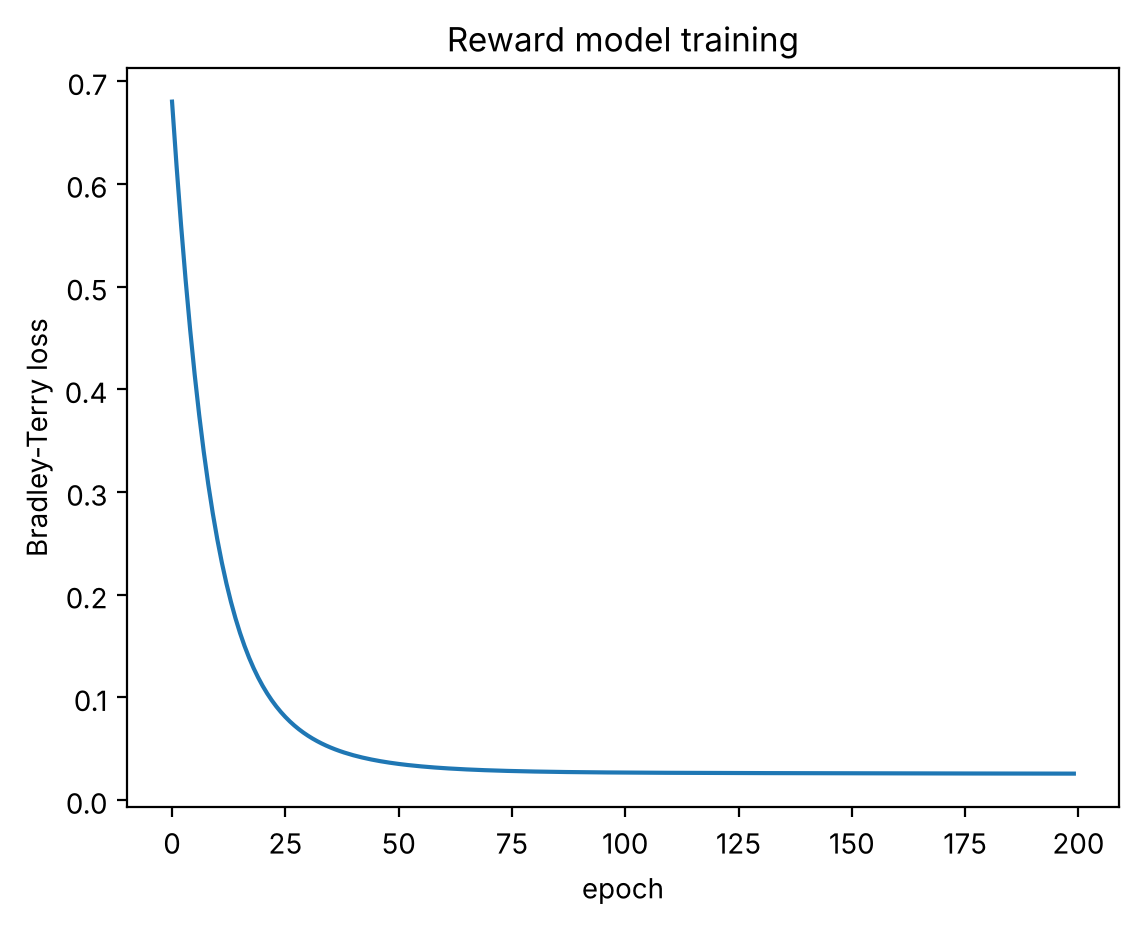

In [6]:
opt = torch.optim.Adam(reward_model.parameters(), lr=0.01, weight_decay=0.01)
history = []
for epoch in range(200):
    r_c, r_r = reward_model(Xc_train), reward_model(Xr_train)
    loss = bt_loss(r_c, r_r)
    opt.zero_grad(); loss.backward(); opt.step()
    acc = (r_c > r_r).float().mean().item()
    history.append(loss.item())
    if epoch % 40 == 0:
        print(f"epoch {epoch:3d}  loss {loss.item():.4f}  train pair accuracy {acc:.2f}")
plt.plot(history); plt.xlabel("epoch"); plt.ylabel("Bradley-Terry loss"); plt.title("Reward model training"); plt.show()

## Step 7 - Test on unseen topics

**Pair accuracy** = fraction of test pairs where the chosen answer gets the higher score. Real reward models often land around 65-75% on hard human data, because humans themselves disagree. Our synthetic data is much easier.

In [7]:
with torch.no_grad():
    margin = reward_model(Xc_test) - reward_model(Xr_test)
print("test pair accuracy:", (margin > 0).float().mean().item())

test pair accuracy: 1.0


## Step 8 - What did it learn?

Because the model is linear, each word's weight tells us how much it raises or lowers the reward. This is the big advantage of a tiny model for teaching: we can open the box.

In [8]:
w = reward_model.weight[0].detach().numpy()
vocab = np.array(vec.get_feature_names_out())
order = np.argsort(w)
print("most NEGATIVE words:", list(vocab[order[:10]]))
print("most POSITIVE words:", list(vocab[order[-10:]]))

most NEGATIVE words: ['trying', 'want', 'silly', 'just', 'figure', 'know', 'easy', 'search', 'don', 'online']
most POSITIVE words: ['month', 'set', 'recent', 'add', 'track', 'budget', 'payday', 'spending', 'savings', 'settings']


## Step 9 - Score new answers

Now the reward model can score *any* answer without a human. This is exactly how it is used in stage 3 of RLHF: the policy writes answers and the reward model scores them.

In [9]:
def score(text):
    with torch.no_grad():
        return reward_model(feats([text])).item()

candidates = [
    "To start running, begin with short run-walk sessions and increase slowly. Good luck!",
    "Just do it. It's easy.",
    "Of course. Hope this helps!",
]
for c in candidates:
    print(f"{score(c):+6.2f}  {c}")

 +0.57  To start running, begin with short run-walk sessions and increase slowly. Good luck!
 -0.62  Just do it. It's easy.
 +0.43  Of course. Hope this helps!


## Step 10 - Reward hacking

A reward model is only an *approximation* of human taste. If we optimise hard against it, we find answers that score high but are nonsense. Below, an answer stuffed with "positive" words and no real meaning beats a short, genuinely useful one. This is **reward hacking**, and it is why PPO adds a **KL penalty** that keeps the policy close to the reference model (see `concepts.md` section 6.3).

In [10]:
top_words = " ".join(vocab[order[-15:]])
hacked = f"{top_words} {top_words} {top_words}"
honest = "Rinse the rice, add water, boil, then simmer."
print(f"honest answer : {score(honest):+7.2f}   '{honest}'")
print(f"hacked answer : {score(hacked):+7.2f}   '{hacked[:70]}...'")

honest answer :   +1.77   'Rinse the rice, add water, boil, then simmer.'
hacked answer :  +16.89   'clear boil water minutes reset month set recent add track budget payda...'


## What you learned

- Preference pairs -> reward model, trained with the Bradley-Terry loss.
- A reward model turns "which is better?" into a number for any answer.
- It can be fooled (reward hacking), so RLHF keeps the policy close to a reference.
- Next: `03-dpo-loss-demo.ipynb` skips the reward model entirely.